### Installing required libraries

In [167]:
!pip install seaborn
!pip install missingno
!pip install xgboost
!pip install catboost
!pip install regex
!pip install scikit-learn
!pip install pandas
!pip install numpy
!pip install imblearn
!pip install lightgbm
!pip install polar


### Importing all libraries 

In [168]:
import pandas as pd   # data processing, CSV file I/O (e.g. pd.read_csv)
import numpy as np   # linear algebra
import matplotlib.pyplot as plt  #graphs and plots
import seaborn as sns   #data visualizations 
import csv # Some extra functionalities for csv  files - reading it as a dictionary
from lightgbm import LGBMClassifier #sklearn is for machine learning and statistical modeling including classification, regression, clustering and dimensionality reduction 

from sklearn.model_selection import train_test_split, cross_validate   #break up dataset into train and test sets

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler


# importing python library for working with missing data
import missingno as msno
# To install missingno use: !pip install missingno
import re    # This library is used to perform regex pattern matching

# import various functions from sklearn
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import GradientBoostingClassifier
from catboost import CatBoostClassifier
import xgboost as xgb
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, classification_report, make_scorer
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split

### Import additional items as needed...

In [169]:
from sklearn.model_selection import KFold,cross_val_score, RepeatedStratifiedKFold,StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import OneHotEncoder,StandardScaler,PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer,SimpleImputer
from sklearn.compose import make_column_transformer
from imblearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from imblearn.over_sampling import SMOTE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, balanced_accuracy_score,\
                            precision_score, recall_score, roc_auc_score,\
                            classification_report, f1_score # removed plot_roc_curve and plot_confusion_matrix as they are deprecated

import plotly 
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
from plotly.offline import iplot
from plotly.subplots import make_subplots
import plotly.figure_factory as ff

import warnings
warnings.filterwarnings("ignore")

### Loading CSV data 

In [170]:
diabetes = pd.read_csv('raw/diabetic_data.csv')

# CLEANING AND TRANSFORMING THE DATASET

In [171]:
# Removal of records from discharge disposition 11, 13, 14, 19, 20, 21 as these patients were either discharged to hospice care or died during their hospital stay.
# diabetes = diabetes[~diabetes['discharge_disposition_id'].isin([11, 13, 14, 19, 20, 21])]

# lets talk i just checked the contents we dont wnat to remove them because almost all of them are being readmitted within 30 days so we will keep them in the dataset for now and see how it goes with the model performance.

In [172]:
#@title GENDER ENCODING
# Keep only Male and Female rows
diabetes = diabetes[diabetes['gender'].isin(['Male', 'Female'])].copy()

# Create indicator: 1 = Male, 0 = Female
diabetes['GenderMale'] = (diabetes['gender'] == 'Male').astype(int)

In [173]:
#@title AGE ENCODING
# Convert everything to string and strip spaces
diabetes['age'] = diabetes['age'].astype(str).str.strip()

# Mapping age ranges to numeric midpoint values
age_map = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}

# Apply mapping
diabetes['age'] = diabetes['age'].map(age_map)

In [174]:
#@title ER/URGENT CARE ADMISSION CODING
# Created a new column ERAdmission.
# ERAdmission = 1 if admission_type_id is 1 or 2 (Emergency/Urgent), otherwise 0.

diabetes['ERAdmission'] = diabetes['admission_type_id'].isin([1, 2]).astype(int)

In [175]:
#@title DIABEST MEDICATION ENCODING
# replacing No with 0 and Yes with 1 for if the patient has diabetic medications or not
diabetes['diabetesMed'] = diabetes['diabetesMed'].apply(
    lambda x: 0 if x == "No" else 1
)

In [176]:
#@title READMITTED ENCODING
# Created indicator column for readmission within 30 days
# readmit_less_30 = 1 if readmitted is "<30", else 0

diabetes['readmit_less_30'] = (diabetes['readmitted'] == '<30').astype(int)

In [177]:
#@title RACE ENCODING
diabetes['RaceCaucasian'] = (diabetes['race'] == 'Caucasian').astype(int)
diabetes['RaceAfricanAmerican'] = (diabetes['race'] == 'AfricanAmerican').astype(int)
diabetes['RaceOther'] = (~diabetes['race'].isin(['Caucasian', 'AfricanAmerican'])).astype(int)

In [178]:
#@title ICD-9 CATEGORIZATION
# 1. Map ICD-9 codes
def categorize_icd9_chapter(code):
    """Maps ICD-9 codes to 17 main chapters + 2 supplemental categories"""
    if pd.isna(code):
        return "Missing"

    code_str = str(code).strip()

    # Supplemental codes
    if code_str.startswith('V'):
        return "V-codes: Factors Influencing Health Status"
    if code_str.startswith('E'):
        return "E-codes: External Causes of Injury"

    # Extract numeric part
    try:
        numeric_part = ''.join(filter(str.isdigit, code_str))
        if not numeric_part:
            return "Unmapped"
        code_num = int(numeric_part[:3])
    except:
        return "Unmapped"

    # ICD-9 chapter ranges
    chapter_map = {
        range(1, 140): "Infectious and Parasitic Diseases",
        range(140, 240): "Neoplasms (Cancers/Tumors)",
        range(240, 280): "Endocrine, Nutritional, Metabolic Diseases",
        range(280, 290): "Diseases of Blood and Blood-forming Organs",
        range(290, 320): "Mental Disorders",
        range(320, 390): "Diseases of Nervous System and Sense Organs",
        range(390, 460): "Diseases of Circulatory System",
        range(460, 520): "Diseases of Respiratory System",
        range(520, 580): "Diseases of Digestive System",
        range(580, 630): "Diseases of Genitourinary System",
        range(630, 680): "Complications of Pregnancy, Childbirth, Puerperium",
        range(680, 710): "Diseases of Skin and Subcutaneous Tissue",
        range(710, 740): "Diseases of Musculoskeletal System and Connective Tissue",
        range(740, 760): "Congenital Anomalies",
        range(760, 780): "Conditions Originating in Perinatal Period",
        range(780, 800): "Symptoms, Signs, Ill-defined Conditions",
        range(800, 1000): "Injury and Poisoning"
    }

    for code_range, chapter_name in chapter_map.items():
        if code_num in code_range:
            return chapter_name

    return "Unmapped"


In [179]:
#@title CATEGORIZING PRIMARY DIAGNOSIS
# Applying categorization the priamry diagnosis column diag_1
diabetes['Primary_Diagnosis'] = diabetes['diag_1'].apply(categorize_icd9_chapter)
print("Created diag_1_chapter")

print("\nChapter Distribution for Primary Diagnosis (diag_1_chapter):")
print(diabetes['Primary_Diagnosis'].value_counts().head(20))


Created diag_1_chapter

Chapter Distribution for Primary Diagnosis (diag_1_chapter):
Primary_Diagnosis
Diseases of Circulatory System                              30335
Endocrine, Nutritional, Metabolic Diseases                  11459
Diseases of Respiratory System                              10407
Diseases of Digestive System                                 9208
Symptoms, Signs, Ill-defined Conditions                      7636
Injury and Poisoning                                         6972
Diseases of Genitourinary System                             5078
Diseases of Musculoskeletal System and Connective Tissue     4957
Neoplasms (Cancers/Tumors)                                   3433
Infectious and Parasitic Diseases                            2768
Diseases of Skin and Subcutaneous Tissue                     2530
Mental Disorders                                             2262
V-codes: Factors Influencing Health Status                   1644
Diseases of Nervous System and Sense Or

In [180]:
#@title DIABETES RELATED DIAGNOSIS INDICATOR
diabetes['diabetes_related'] = diabetes['Primary_Diagnosis'].str.contains(
    'Endocrine', case=False, na=False
).astype(int)


In [181]:
diabetes.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted',
       'GenderMale', 'ERAdmission', 'readmit_less_30', 'RaceCaucasian',
       'RaceAfricanA

In [182]:
#@title drop 1 intial columns
# Dropping unnecessary columns due to high missing values and low relevance
cleandiabetes = diabetes.drop([
    'race', 'weight', 'gender',
    'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
    'payer_code', 'medical_specialty',
    'diag_1', 'diag_2', 'diag_3',
    'max_glu_serum', 'A1Cresult',
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
    'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
    'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
    'tolazamide', 'examide', 'citoglipton', 'insulin',
    'glyburide-metformin', 'glipizide-metformin',
    'glimepiride-pioglitazone', 'metformin-rosiglitazone',
    'metformin-pioglitazone',
    'change', 'readmitted'
], axis=1)

In [183]:
cleandiabetes.head()

,encounter_id,patient_nbr,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,diabetesMed,GenderMale,ERAdmission,readmit_less_30,RaceCaucasian,RaceAfricanAmerican,RaceOther,Primary_Diagnosis,diabetes_related
0,2278392,8222157,5,1,41,0,1,0,0,0,1,0,0,0,0,1,0,0,"Endocrine, Nutritional, Metabolic Diseases",1
1,149190,55629189,15,3,59,0,18,0,0,0,9,1,0,1,0,1,0,0,"Endocrine, Nutritional, Metabolic Diseases",1
2,64410,86047875,25,2,11,5,13,2,0,1,6,1,0,1,0,0,1,0,"Complications of Pregnancy, Childbirth, Puerpe...",0
3,500364,82442376,35,2,44,1,16,0,0,0,7,1,1,1,0,1,0,0,Infectious and Parasitic Diseases,0
4,16680,42519267,45,1,51,0,8,0,0,0,5,1,1,1,0,1,0,0,Neoplasms (Cancers/Tumors),0


### Creating 3 Dataframes from cleandiabetes dataset

In [184]:
# Sub1: No changes (just a copy of cleandiabetes)
Sub1 = cleandiabetes.copy()

# Count how many times each patient appears
patient_counts = cleandiabetes['patient_nbr'].value_counts()

# Identify unique and duplicate patient IDs
unique_ids = patient_counts[patient_counts == 1].index
duplicate_ids = patient_counts[patient_counts > 1].index

# Sub2: Only unique patients (remove duplicates)
Sub2 = cleandiabetes[cleandiabetes['patient_nbr'].isin(unique_ids)].copy()

# Sub3: Only duplicate patients
Sub3 = cleandiabetes[cleandiabetes['patient_nbr'].isin(duplicate_ids)].copy()

In [185]:
print("Sub1 rows:", len(Sub1))
print("Sub2 rows:", len(Sub2))
print("Sub3 rows:", len(Sub3))

print("Unique patients:", len(unique_ids))
print("Duplicate patients:", len(duplicate_ids))

Sub1 rows: 101763
Sub2 rows: 54742
Sub3 rows: 47021
Unique patients: 54742
Duplicate patients: 16773


In [186]:
#removing primary_diagnosis column as they are not relevant to our analysis
cols_to_drop = ['Primary_Diagnosis', 'encounter_id', 'patient_nbr']

Sub1 = Sub1.drop(columns=cols_to_drop)
Sub2 = Sub2.drop(columns=cols_to_drop)
Sub3 = Sub3.drop(columns=cols_to_drop)

In [187]:
Sub1.columns

Index(['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'number_diagnoses', 'diabetesMed', 'GenderMale',
       'ERAdmission', 'readmit_less_30', 'RaceCaucasian',
       'RaceAfricanAmerican', 'RaceOther', 'diabetes_related'],
      dtype='str')

In [188]:
numerical = ['time_in_hospital',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient',
       'number_diagnoses',]

### MISSING DATA

In [189]:
def missing(df):
    missing_number = df.isnull().sum().sort_values(ascending=False)
    missing_percent = (df.isnull().sum() / df.isnull().count()).sort_values(ascending=False)
    missing_values = pd.concat([missing_number, missing_percent], axis=1,
                               keys=['Missing_Number', 'Missing_Percent'])
    return missing_values

In [190]:
print("Missing Data in Sub1:")
display(missing(Sub1))

print("\nMissing Data in Sub2:")
display(missing(Sub2))

print("\nMissing Data in Sub3:")
display(missing(Sub3))

Missing Data in Sub1:


,Missing_Number,Missing_Percent
age,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
number_outpatient,0,0.0
number_emergency,0,0.0
number_inpatient,0,0.0
number_diagnoses,0,0.0
diabetesMed,0,0.0



Missing Data in Sub2:


,Missing_Number,Missing_Percent
age,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
number_outpatient,0,0.0
number_emergency,0,0.0
number_inpatient,0,0.0
number_diagnoses,0,0.0
diabetesMed,0,0.0



Missing Data in Sub3:


,Missing_Number,Missing_Percent
age,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
number_outpatient,0,0.0
number_emergency,0,0.0
number_inpatient,0,0.0
number_diagnoses,0,0.0
diabetesMed,0,0.0


### VISUALING MISSING DATA

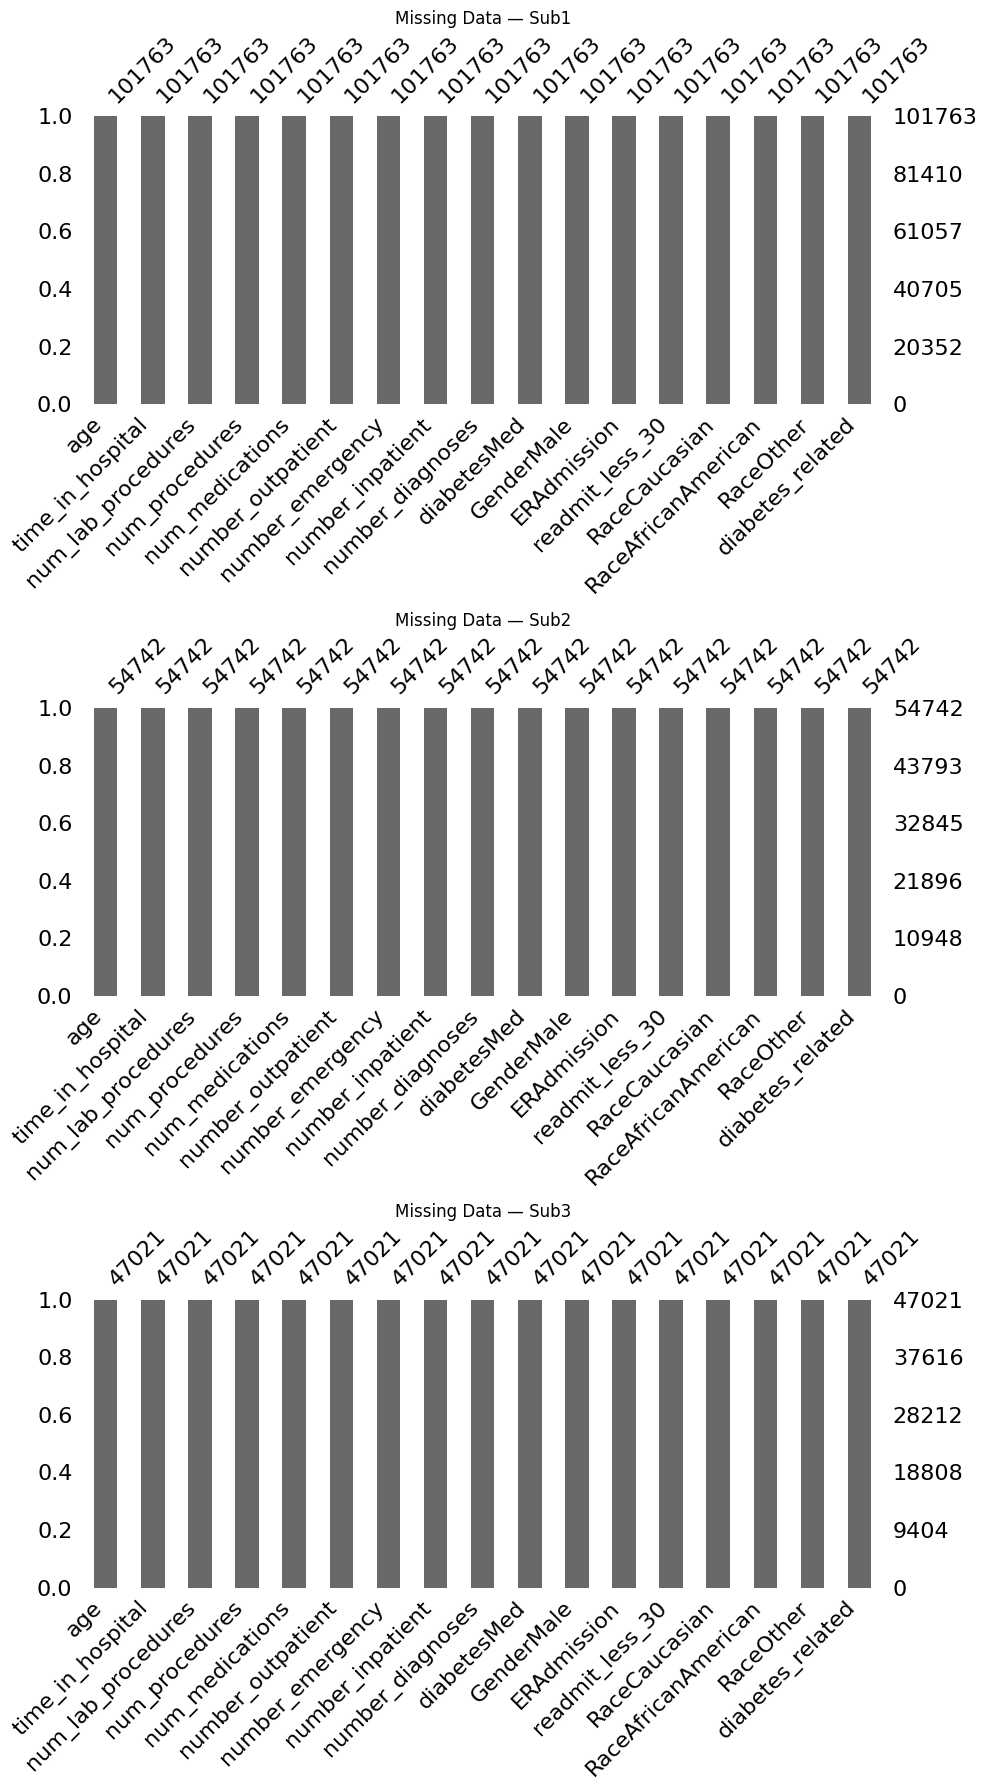

In [191]:
# Visualizing the missing data to get more idea
fig, axes = plt.subplots(3, 1, figsize=(10, 18))

msno.bar(Sub1, ax=axes[0])
axes[0].set_title("Missing Data — Sub1")

msno.bar(Sub2, ax=axes[1])
axes[1].set_title("Missing Data — Sub2")

msno.bar(Sub3, ax=axes[2])
axes[2].set_title("Missing Data — Sub3")

plt.tight_layout()
plt.show()


### CORRELATION

In [192]:
#@title Correlation Matrices
print("Correlation Matrix for Sub1")
display(Sub1[numerical].corr())

print("\nCorrelation Matrix for Sub2")
display(Sub2[numerical].corr())

print("\nCorrelation Matrix for Sub3")
display(Sub3[numerical].corr())

Correlation Matrix for Sub1


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
time_in_hospital,1.000000,0.318429,0.191497,0.466137,-0.008919,-0.009683,0.073619,0.220153
num_lab_procedures,0.318429,1.000000,0.058105,0.268176,-0.007606,-0.002282,0.039225,0.152737
num_procedures,0.191497,0.058105,1.000000,0.385761,-0.024813,-0.038175,-0.066226,0.073769
num_medications,0.466137,0.268176,0.385761,1.000000,0.045198,0.013180,0.064196,0.261529
number_outpatient,-0.008919,-0.007606,-0.024813,0.045198,1.000000,0.091457,0.107334,0.094148
number_emergency,-0.009683,-0.002282,-0.038175,0.013180,0.091457,1.000000,0.266557,0.055536
number_inpatient,0.073619,0.039225,-0.066226,0.064196,0.107334,0.266557,1.000000,0.104703
number_diagnoses,0.220153,0.152737,0.073769,0.261529,0.094148,0.055536,0.104703,1.000000



Correlation Matrix for Sub2


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
time_in_hospital,1.000000,0.340706,0.174805,0.466068,-0.013626,-0.007322,0.073720,0.235539
num_lab_procedures,0.340706,1.000000,0.039485,0.257319,-0.008380,0.021545,0.085350,0.162946
num_procedures,0.174805,0.039485,1.000000,0.407310,-0.015250,-0.034114,-0.020113,0.092049
num_medications,0.466068,0.257319,0.407310,1.000000,0.024341,0.001787,0.037141,0.259580
number_outpatient,-0.013626,-0.008380,-0.015250,0.024341,1.000000,0.097273,0.065939,0.078612
number_emergency,-0.007322,0.021545,-0.034114,0.001787,0.097273,1.000000,0.133243,0.049577
number_inpatient,0.073720,0.085350,-0.020113,0.037141,0.065939,0.133243,1.000000,0.072854
number_diagnoses,0.235539,0.162946,0.092049,0.259580,0.078612,0.049577,0.072854,1.000000



Correlation Matrix for Sub3


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
time_in_hospital,1.000000,0.296412,0.226859,0.463961,-0.015717,-0.024779,0.051073,0.187794
num_lab_procedures,0.296412,1.000000,0.080391,0.285403,-0.004733,-0.010826,0.041590,0.147439
num_procedures,0.226859,0.080391,1.000000,0.370072,-0.021253,-0.030856,-0.053436,0.076022
num_medications,0.463961,0.285403,0.370072,1.000000,0.057240,0.010424,0.061334,0.253969
number_outpatient,-0.015717,-0.004733,-0.021253,0.057240,1.000000,0.079625,0.087098,0.092988
number_emergency,-0.024779,-0.010826,-0.030856,0.010424,0.079625,1.000000,0.256625,0.042113
number_inpatient,0.051073,0.041590,-0.053436,0.061334,0.087098,0.256625,1.000000,0.060985
number_diagnoses,0.187794,0.147439,0.076022,0.253969,0.092988,0.042113,0.060985,1.000000


In [193]:
print("Correlation for Sub1 grouped by readmit_less_30")
display(Sub1.groupby('readmit_less_30')[numerical].corr())

print("\nCorrelation for Sub2 grouped by readmit_less_30")
display(Sub2.groupby('readmit_less_30')[numerical].corr())

print("\nCorrelation for Sub3 grouped by readmit_less_30")
display(Sub3.groupby('readmit_less_30')[numerical].corr())

Correlation for Sub1 grouped by readmit_less_30


time_in_hospital  num_lab_procedures  \
readmit_less_30                                                            
0               time_in_hospital            1.000000            0.317966   
                num_lab_procedures          0.317966            1.000000   
                num_procedures              0.184436            0.052939   
                num_medications             0.463447            0.263577   
                number_outpatient          -0.008027           -0.009679   
                number_emergency           -0.003929            0.004752   
                number_inpatient            0.081365            0.044138   
                number_diagnoses            0.222743            0.153452   
1               time_in_hospital            1.000000            0.317655   
                num_lab_procedures          0.317655            1.000000   
                num_procedures              0.256572            0.104734   
                num_medications             0.479381            0.300945   
                number_outpatient          -0.022948            0.005296   
                number_emergency           -0.054951           -0.046064   
                number_inpatient            0.011970            0.004974   
                number_diagnoses            0.182704            0.138825   

                                    num_procedures  num_medications  \
readmit_less_30                                                       
0               time_in_hospital          0.184436         0.463447   
                num_lab_procedures        0.052939         0.263577   
                num_procedures            1.000000         0.385402   
                num_medications           0.385402         1.000000   
                number_outpatient        -0.023116         0.044064   
                number_emergency         -0.036941         0.017059   
                number_inpatient         -0.063103         0.066991   
                number_diagnoses          0.071891         0.261232   
1               time_in_hospital          0.256572         0.479381   
                num_lab_procedures        0.104734         0.300945   
                num_procedures            1.000000         0.396435   
                num_medications           0.396435         1.000000   
                number_outpatient        -0.036554         0.048016   
                number_emergency         -0.044692        -0.019015   
                number_inpatient         -0.084559         0.028102   
                number_diagnoses          0.098215         0.251496   

                                    number_outpatient  number_emergency  \
readmit_less_30                                                           
0               time_in_hospital            -0.008027         -0.003929   
                num_lab_procedures          -0.009679          0.004752   
                num_procedures              -0.023116         -0.036941   
                num_medications              0.044064          0.017059   
                number_outpatient            1.000000          0.091213   
                number_emergency             0.091213          1.000000   
                number_inpatient             0.106594          0.241276   
                number_diagnoses             0.093655          0.056898   
1               time_in_hospital            -0.022948         -0.054951   
                num_lab_procedures           0.005296         -0.046064   
                num_procedures              -0.036554         -0.044692   
                num_medications              0.048016         -0.019015   
                number_outpatient            1.000000          0.094259   
                number_emergency             0.094259          1.000000   
                number_inpatient             0.113480          0.316596   
                number_diagnoses             0.091372          0.036837   

                                    n


Correlation for Sub2 grouped by readmit_less_30


time_in_hospital  num_lab_procedures  \
readmit_less_30                                                            
0               time_in_hospital            1.000000            0.341730   
                num_lab_procedures          0.341730            1.000000   
                num_procedures              0.173917            0.038961   
                num_medications             0.465509            0.257099   
                number_outpatient          -0.012693           -0.010347   
                number_emergency           -0.005751            0.020381   
                number_inpatient            0.073526            0.081239   
                number_diagnoses            0.236242            0.162421   
1               time_in_hospital            1.000000            0.270163   
                num_lab_procedures          0.270163            1.000000   
                num_procedures              0.205736            0.060110   
                num_medications             0.462984            0.229215   
                number_outpatient          -0.052753            0.013457   
                number_emergency           -0.062541            0.013484   
                number_inpatient            0.021591            0.065266   
                number_diagnoses            0.177899            0.117512   

                                    num_procedures  num_medications  \
readmit_less_30                                                       
0               time_in_hospital          0.173917         0.465509   
                num_lab_procedures        0.038961         0.257099   
                num_procedures            1.000000         0.408446   
                num_medications           0.408446         1.000000   
                number_outpatient        -0.016164         0.024343   
                number_emergency         -0.034876         0.002371   
                number_inpatient         -0.018008         0.035041   
                number_diagnoses          0.090042         0.259828   
1               time_in_hospital          0.205736         0.462984   
                num_lab_procedures        0.060110         0.229215   
                num_procedures            1.000000         0.384757   
                num_medications           0.384757         1.000000   
                number_outpatient         0.007021         0.011883   
                number_emergency         -0.018731        -0.027615   
                number_inpatient         -0.048872         0.018454   
                number_diagnoses          0.157510         0.225604   

                                    number_outpatient  number_emergency  \
readmit_less_30                                                           
0               time_in_hospital            -0.012693         -0.005751   
                num_lab_procedures          -0.010347          0.020381   
                num_procedures              -0.016164         -0.034876   
                num_medications              0.024343          0.002371   
                number_outpatient            1.000000          0.095315   
                number_emergency             0.095315          1.000000   
                number_inpatient             0.066823          0.133168   
                number_diagnoses             0.078756          0.048283   
1               time_in_hospital            -0.052753         -0.062541   
                num_lab_procedures           0.013457          0.013484   
                num_procedures               0.007021         -0.018731   
                num_medications              0.011883         -0.027615   
                number_outpatient            1.000000          0.124669   
                number_emergency             0.124669          1.000000   
                number_inpatient             0.055868          0.134462   
                number_diagnoses             0.059651          0.056516   

                                    n


Correlation for Sub3 grouped by readmit_less_30


time_in_hospital  num_lab_procedures  \
readmit_less_30                                                            
0               time_in_hospital            1.000000            0.288638   
                num_lab_procedures          0.288638            1.000000   
                num_procedures              0.216469            0.073190   
                num_medications             0.458750            0.276475   
                number_outpatient          -0.015362           -0.007388   
                number_emergency           -0.016795           -0.001128   
                number_inpatient            0.062968            0.050536   
                number_diagnoses            0.188471            0.147097   
1               time_in_hospital            1.000000            0.327947   
                num_lab_procedures          0.327947            1.000000   
                num_procedures              0.268246            0.109205   
                num_medications             0.483495            0.319894   
                number_outpatient          -0.016202            0.008174   
                number_emergency           -0.054494           -0.043950   
                number_inpatient            0.014885            0.016169   
                number_diagnoses            0.184787            0.148717   

                                    num_procedures  num_medications  \
readmit_less_30                                                       
0               time_in_hospital          0.216469         0.458750   
                num_lab_procedures        0.073190         0.276475   
                num_procedures            1.000000         0.362148   
                num_medications           0.362148         1.000000   
                number_outpatient        -0.016208         0.058246   
                number_emergency         -0.027220         0.018812   
                number_inpatient         -0.044680         0.071571   
                number_diagnoses          0.073631         0.253115   
1               time_in_hospital          0.268246         0.483495   
                num_lab_procedures        0.109205         0.319894   
                num_procedures            1.000000         0.399940   
                num_medications           0.399940         1.000000   
                number_outpatient        -0.043930         0.055282   
                number_emergency         -0.045455        -0.018925   
                number_inpatient         -0.084670         0.030256   
                number_diagnoses          0.085606         0.257638   

                                    number_outpatient  number_emergency  \
readmit_less_30                                                           
0               time_in_hospital            -0.015362         -0.016795   
                num_lab_procedures          -0.007388         -0.001128   
                num_procedures              -0.016208         -0.027220   
                num_medications              0.058246          0.018812   
                number_outpatient            1.000000          0.078010   
                number_emergency             0.078010          1.000000   
                number_inpatient             0.081197          0.226441   
                number_diagnoses             0.092338          0.044643   
1               time_in_hospital            -0.016202         -0.054494   
                num_lab_procedures           0.008174         -0.043950   
                num_procedures              -0.043930         -0.045455   
                num_medications              0.055282         -0.018925   
                number_outpatient            1.000000          0.091534   
                number_emergency             0.091534          1.000000   
                number_inpatient             0.117585          0.322827   
                number_diagnoses             0.096884          0.034266   

                                    n

| Color Range      | Intensity    | Correlation         | Meaning                                    |
| ---------------- | ------------ | ------------------- | ------------------------------------------ |
| Dark Red         | 0.6 to 1.0   | Strong positive     | Variables move together (both ↑ or both ↓) |
| Light Red/Orange | 0.2 to 0.6   | Moderate positive   | Variables tend to move together            |
| White/Pale       | -0.2 to +0.2 | Weak/No correlation | No linear relationship                     |
| Light Blue       | -0.2 to -0.6 | Moderate negative   | Variables move opposite (one ↑, other ↓)   |
| Dark Blue        | -0.6 to -1.0 | Strong negative     | Variables strongly oppose each other       |

|CORRELATION| ACTION                      |
|-----------|-----------------------------|
| ≥ +0.70   | Feature engineering/PCA     |
| +0.50-0.69| Keep both (important pair)  |
| +0.30-0.49| Moderate (conditional keep) |
| < ±0.30   | Weak (consider dropping)    |


In [194]:
#@title Reusable Correlation Heatmaps
def plot_corr_heatmap(df, numerical, title):
    """
    Plots a lower‑triangle correlation heatmap for a given dataframe.
    """
    corr_matrix = df[numerical].corr()

    # Mask upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap='coolwarm',
        center=0,
        square=True,
        linewidths=0.5,
        fmt='.2f',
        mask=mask
    )

    plt.title(title, fontsize=14)
    plt.tight_layout()
    plt.show()


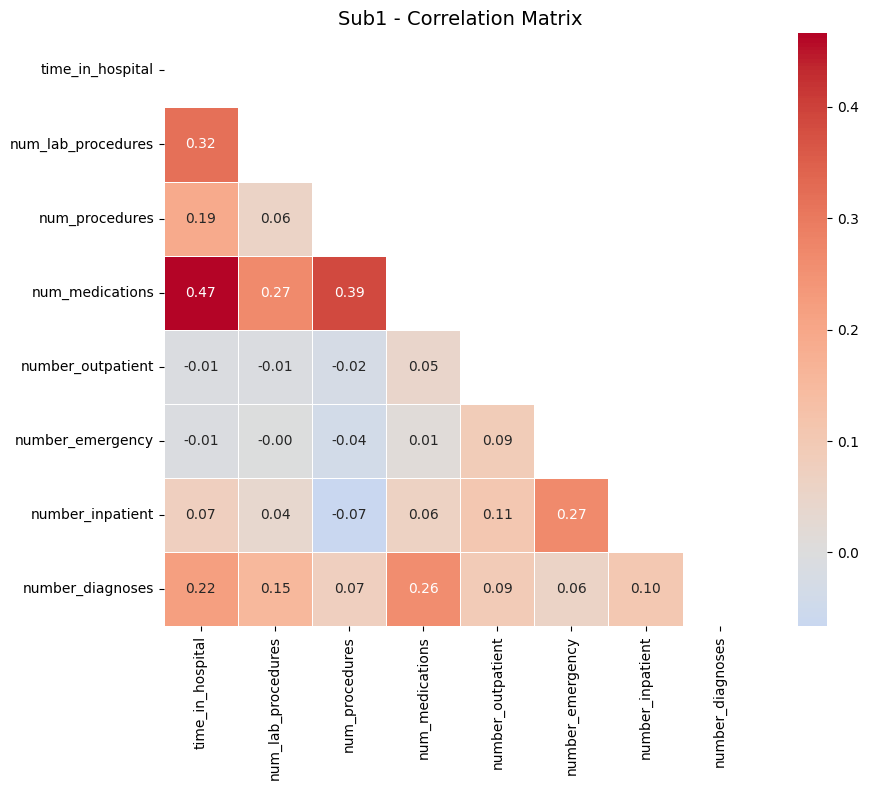

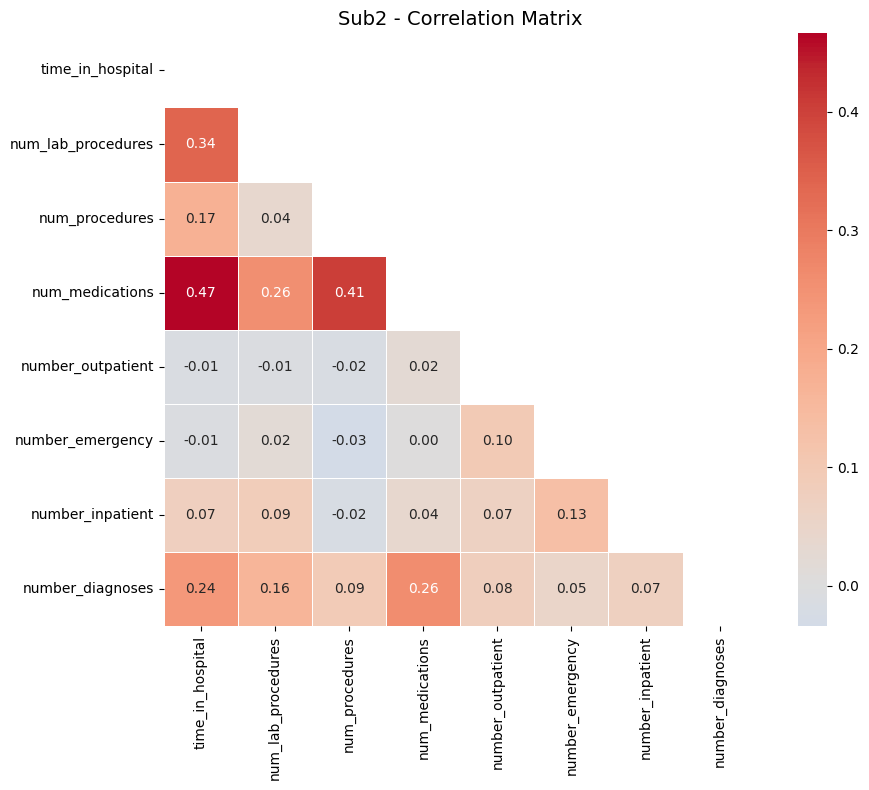

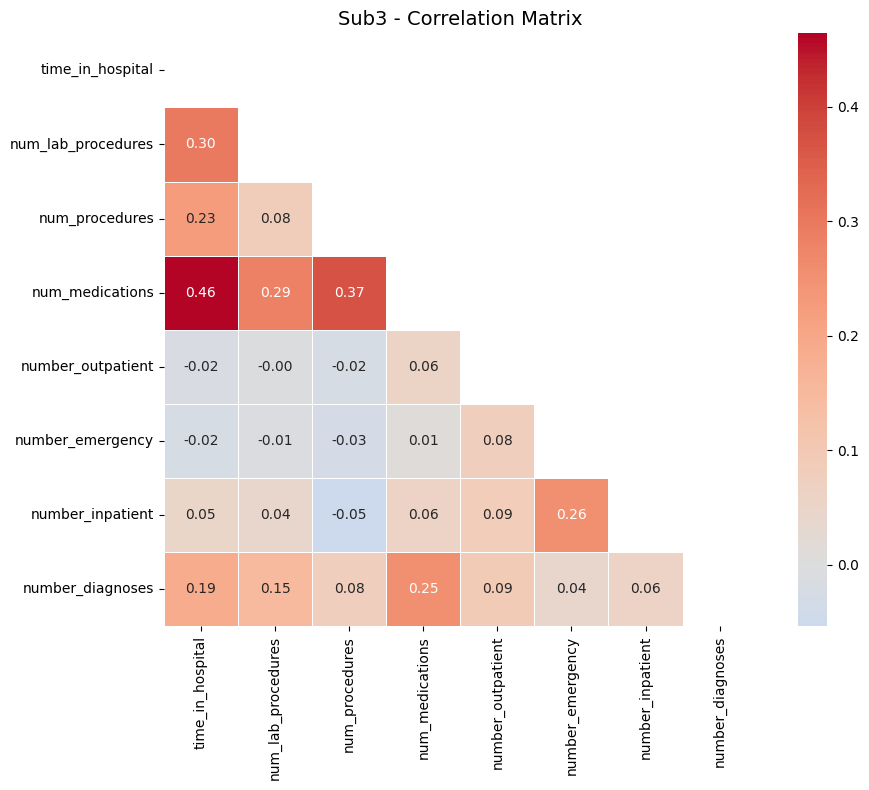

In [195]:
plot_corr_heatmap(Sub1, numerical, "Sub1 - Correlation Matrix")
plot_corr_heatmap(Sub2, numerical, "Sub2 - Correlation Matrix")
plot_corr_heatmap(Sub3, numerical, "Sub3 - Correlation Matrix")

In [196]:
print("Sub1 correlation (age vs readmit_less_30)")
display(Sub1[['age', 'readmit_less_30']].corr())

print("\nSub2 correlation (age vs readmit_less_30)")
display(Sub2[['age', 'readmit_less_30']].corr())

print("\nSub3 correlation (age vs readmit_less_30)")
display(Sub3[['age', 'readmit_less_30']].corr())

Sub1 correlation (age vs readmit_less_30)


,age,readmit_less_30
age,1.000000,0.017638
readmit_less_30,0.017638,1.000000



Sub2 correlation (age vs readmit_less_30)


,age,readmit_less_30
age,1.000000,0.047585
readmit_less_30,0.047585,1.000000



Sub3 correlation (age vs readmit_less_30)


,age,readmit_less_30
age,1.000000,-0.016643
readmit_less_30,-0.016643,1.000000


# Breaking the data up into Train & Test

In [197]:
#@title Setting Up Data for Modeling
DataTesting = Sub1.copy() #change it to sub2 or Sub3 to test each dataset

In [198]:
# Step 1: Split cleandiabetes into Train (70%) and Temp (30%)
train_df, temp_df = train_test_split(
    DataTesting,
    test_size=0.30,        # 30% goes to temp (valid + test)
    random_state=42,       # ensures reproducibility
    shuffle=True           # shuffles before splitting
)


# Step 2: Split Temp into Validation (15%) and Test (15%)
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,        # half of temp = 15% of total
    random_state=42,
    shuffle=True
)

# Step 3: Reset indexes for cleanliness
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)


# Step 4: Just Making Sure Check
print("Train size:", len(train_df))
print("Validation size:", len(valid_df))
print("Test size:", len(test_df))
print("Total:", len(train_df) + len(valid_df) + len(test_df))


Train size: 71234
Validation size: 15264
Test size: 15265
Total: 101763


In [199]:
DataTesting.readmit_less_30.value_counts()

readmit_less_30
0    90406
1    11357
Name: count, dtype: int64

In [200]:
train_df.readmit_less_30.value_counts()

readmit_less_30
0    63318
1     7916
Name: count, dtype: int64

In [201]:
valid_df.readmit_less_30.value_counts()

readmit_less_30
0    13519
1     1745
Name: count, dtype: int64

In [202]:
test_df.readmit_less_30.value_counts()

readmit_less_30
0    13569
1     1696
Name: count, dtype: int64

### Ways to Fix/Treat the Imbalance in the Data
Imbalance in the data means that one of the classes in the data is too less as compared to the others. Typically, it is better to balance the data in some way to give the positives more weight. There are 3 strategies that are typically utilized:

#### Random Oversampling: 
This technique involves randomly duplicating examples from the minority class in the training dataset. 
This can help balance the class distribution but may lead to overfitting since it replicates existing data points.

In [203]:
from sklearn.utils import resample
import pandas as pd

def balance_random_oversample(df, target='readmit_less_30', random_state=42):
    """
    Random oversampling of the minority class.
    Returns a balanced DataFrame with the same columns as the input.
    """

    # Split classes
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    # Oversample minority class
    df_pos_over = resample(
        df_pos,
        replace=True,
        n_samples=len(df_neg),
        random_state=random_state
    )

    # Combine + shuffle
    df_bal = (
        pd.concat([df_neg, df_pos_over])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### SMOTE 
(Synthetic Minority Over-sampling Technique): SMOTE generates synthetic examples of the minority class by interpolating between existing minority class examples. 
This can help create a more balanced dataset without simply duplicating existing data points, which may reduce the risk of overfitting compared to random oversampling.



In [204]:
from imblearn.over_sampling import SMOTE
import pandas as pd

def balance_smote(df, target='readmit_less_30', random_state=42):
    """
    Apply SMOTE to oversample the minority class.
    Returns a balanced DataFrame with the same columns as the input.
    """

    sm = SMOTE(random_state=random_state)

    X = df.drop(target, axis=1)
    y = df[target]

    # SMOTE resampling
    X_bal, y_bal = sm.fit_resample(X, y)

    # Rebuild DataFrame
    df_bal = pd.concat(
        [
            pd.DataFrame(X_bal, columns=X.columns),
            pd.Series(y_bal, name=target)
        ],
        axis=1
    )

    return df_bal


#### CLASS WEIGHTS
Many machine learning algorithms allow you to assign different weights to classes during training. 
By assigning a higher weight to the minority class, you can make the model pay more attention

In [205]:
from sklearn.linear_model import LogisticRegression

def train_logreg_classweight(train_df, valid_df, test_df,
                             target='readmit_less_30', max_iter=500):
    """
    Train Logistic Regression using class_weight='balanced'.
    Returns the fitted model and all X/y splits.
    """

    # Training split
    X_train = train_df.drop(target, axis=1)
    y_train = train_df[target]

    # Validation split
    X_valid = valid_df.drop(target, axis=1)
    y_valid = valid_df[target]

    # Test split
    X_test = test_df.drop(target, axis=1)
    y_test = test_df[target]

    # Model
    model = LogisticRegression(class_weight='balanced', max_iter=max_iter)
    model.fit(X_train, y_train)

    return model, X_train, y_train, X_valid, y_valid, X_test, y_test


#### RANDOM UNDERSAMPLING

In [206]:
def balance_random_undersample(df, target='readmit_less_30', random_state=42):
    """
    Random undersampling of the majority class.
    Returns a balanced DataFrame with the same columns as the input.
    """

    # Split classes
    df_pos = df[df[target] == 1]   # minority
    df_neg = df[df[target] == 0]   # majority

    # Undersample majority class
    df_neg_under = df_neg.sample(
        n=len(df_pos),
        random_state=random_state
    )

    # Combine + shuffle
    df_bal = (
        pd.concat([df_pos, df_neg_under])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal


In [207]:
def calc_prevalence(y_actual):
    """
    Calculate the prevalence (ratio of positive class = 1)
    in a binary target array or Series.
    """
    y_actual = pd.Series(y_actual)
    return y_actual.mean()

#### Replace XXXX(train_df) to change to use different imbalance technique

In [208]:
# 1. Choose balancing method
train_balanced = balance_random_undersample(train_df)
# or balance_random_oversample(train_df)
# or balance_smote(train_df)
# or train_logreg_classweight(train_df)
# or balance_random_undersample(train_df)

# 2. Check prevalence
print(
    "Train balanced prevalence (n = %d): %.3f" %
    (len(train_balanced), calc_prevalence(train_balanced['readmit_less_30']))
)

train_balanced = balance_random_undersample(train_df) 

Train balanced prevalence (n = 15832): 0.500


In [209]:
train_balanced.readmit_less_30.value_counts()

readmit_less_30
0    7916
1    7916
Name: count, dtype: int64

In [210]:
X_train = train_balanced.drop('readmit_less_30',axis=1)

y_train = train_balanced['readmit_less_30']

X_valid = valid_df.drop('readmit_less_30',axis=1)

y_valid = valid_df['readmit_less_30']

X_test = test_df.drop('readmit_less_30',axis=1)

y_test = test_df['readmit_less_30']

In [211]:
Sub1.columns

Index(['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'number_diagnoses', 'diabetesMed', 'GenderMale',
       'ERAdmission', 'readmit_less_30', 'RaceCaucasian',
       'RaceAfricanAmerican', 'RaceOther', 'diabetes_related'],
      dtype='str')

In [212]:
set1 = [
    'age',
    'time_in_hospital',
    'num_medications',
    'number_inpatient'
]


set2 = [
    'age',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses',
    'ERAdmission'
]


set3 = [
    'age',
    'time_in_hospital',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses',
    'ERAdmission'
]


set4 = [
    'age',
    'time_in_hospital',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses',
    'diabetesMed',
    'RaceCaucasian',
    'RaceAfricanAmerican',
    'RaceOther',
    'GenderMale',
    'ERAdmission'
]


In [213]:
scale_cols = set4

# -----------------------------------------
# 1. Fit the scaler on TRAINING data only
# -----------------------------------------
scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])

# -----------------------------------------
# 2. Transform VALIDATION and TEST sets
# -----------------------------------------
X_valid[scale_cols] = scaler.transform(X_valid[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])


In [214]:
X_train.head()

,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,diabetesMed,GenderMale,ERAdmission,RaceCaucasian,RaceAfricanAmerican,RaceOther,diabetes_related
0,0.551210,-0.854636,29,1,-1.162041,-0.304679,-0.217181,-0.552061,-0.285583,-1.902573,1.085089,-1.592575,0.565290,-0.476946,-0.245506,0
1,-1.333755,-0.519952,55,0,0.445251,0.432323,-0.217181,0.686633,0.788883,0.525604,1.085089,0.627914,0.565290,-0.476946,-0.245506,0
2,-1.333755,-0.519952,71,0,-0.791128,-0.304679,-0.217181,-0.552061,-2.434516,-1.902573,-0.921584,-1.592575,-1.769002,-0.476946,4.073219,0
3,-0.077111,-1.189319,10,2,0.074337,0.432323,-0.217181,0.067286,0.251650,0.525604,-0.921584,-1.592575,0.565290,-0.476946,-0.245506,0
4,0.551210,-0.854636,47,0,0.197975,-0.304679,-0.217181,0.686633,0.788883,0.525604,-0.921584,0.627914,0.565290,-0.476946,-0.245506,0


## Creating and Understanding Models

In [215]:
def calc_specificity(y_actual, y_pred, thresh):
    # calculates specificity
    return sum((y_pred < thresh) & (y_actual == 0)) /sum(y_actual ==0)

def print_report(y_actual, y_pred, thresh = 0.5):
    
    '''
    This function calculates all the metrics to asses the machine learning models.
    
    Params:
    1. y_actual: The actual values for the target variable.
    2. y_pred: The predicted values for the target variable.
    3. thresh: The threshold for the probability to be considered as a positive class. Default value 0.5
    
    Return:
    1. AUC - ROC Curve
    2. Accuracy
    3. Recall
    4. Precision
    5. Specificity
    '''
    
    auc = roc_auc_score(y_actual, y_pred)
    accuracy = accuracy_score(y_actual, (y_pred > thresh))
    recall = recall_score(y_actual, (y_pred > thresh))
    precision = precision_score(y_actual, (y_pred > thresh))
    specificity = calc_specificity(y_actual, y_pred, thresh)
    print('AUC:%.3f'%auc)
    print('accuracy:%.3f'%accuracy)
    print('recall:%.3f'%recall)
    print('precision:%.3f'%precision)
    print('specificity:%.3f'%specificity)
    print('prevalence:%.3f'%calc_prevalence(y_actual))
    print(' ')
    return auc, accuracy, recall, precision, specificity

## Linear Regression

In [216]:
# disable truncation so NumPy prints the entire array
np.set_printoptions(threshold=np.inf)

lnr = LinearRegression()
lnr.fit(X_train, y_train)

y_valid_preds = lnr.predict(X_valid)

In [217]:
print(y_valid_preds)

[0.42525715 0.5935453  0.64662015 0.48164034 0.80421691 0.44960599
 0.59284917 0.32364904 0.47491033 0.46194088 0.56784374 0.37652105
 0.821146   0.51500404 0.51256782 0.51144809 0.39922996 0.54430949
 0.42485289 0.48871746 0.46783299 0.73780029 0.39652237 0.48862649
 0.54539613 0.60432815 0.50588915 0.78072864 0.4645603  0.4986243
 0.528028   0.38955822 0.51557275 0.42049275 0.53275376 0.36264381
 0.4371914  0.66682972 0.43170018 0.64505642 0.46628264 0.56918954
 0.42088185 0.47038571 0.37047717 0.45746438 0.72097167 0.36292397
 0.48210203 0.65560226 0.43961403 0.47976201 0.66244565 0.39240991
 0.40336908 0.50142317 0.31453859 0.48512497 0.45948446 0.65791544
 0.45900197 0.33112852 0.48965351 0.57817766 0.48287192 0.56245701
 0.39315172 0.43175306 0.43996693 0.78804066 0.53458675 0.54006832
 0.39898412 0.39322472 0.48947165 0.52878769 0.48177772 0.45149605
 0.51500898 0.42527244 0.47826351 0.45432764 0.42800367 0.5006893
 0.45180212 0.38673728 0.36326167 0.40934174 0.51617798 0.408666

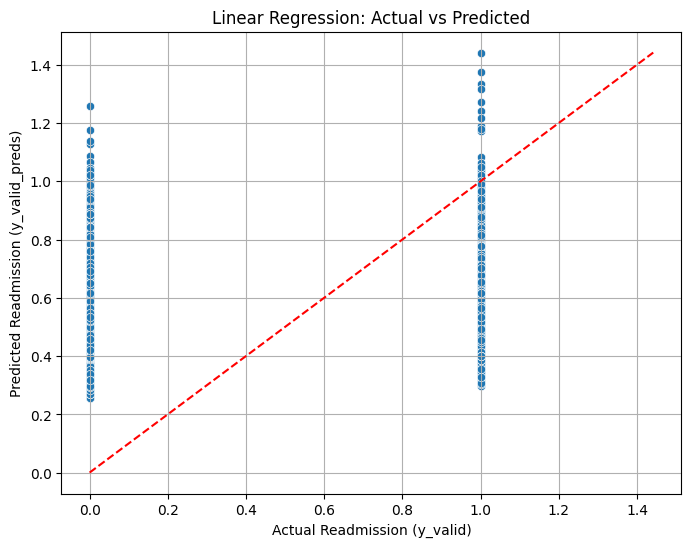

In [218]:
# Create a scatter plot of Actual vs Predicted
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_valid, y=y_valid_preds)

# Add a 45-degree reference line
min_val = min(y_valid.min(), y_valid_preds.min())
max_val = max(y_valid.max(), y_valid_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.xlabel("Actual Readmission (y_valid)")
plt.ylabel("Predicted Readmission (y_valid_preds)")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(True)
plt.show()


## Logistic Regression

In [219]:
lr=LogisticRegression(random_state = 42, solver = 'newton-cg', max_iter = 200)
lr.fit(X_train, y_train)

y_valid_preds = lr.predict_proba(X_valid)[:,1]

print('Metrics for Validation data:')

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,y_valid_preds, 0.5)

Metrics for Validation data:
AUC:0.635
accuracy:0.687
recall:0.468
precision:0.175
specificity:0.715
prevalence:0.114
 


## KNN Model

In [220]:
knn = KNeighborsClassifier(n_neighbors = 100)
knn.fit(X_train, y_train)

knn_preds = knn.predict_proba(X_valid)[:,1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,knn_preds, 0.5)

AUC:0.593
accuracy:0.645
recall:0.452
precision:0.150
specificity:0.613
prevalence:0.114
 


## Stochastic Gradient Descent Model

In [221]:
sgdc = SGDClassifier(loss='log_loss', alpha=0.1, random_state=42)
sgdc.fit(X_train, y_train)

sgd_preds = sgdc.predict_proba(X_valid)[:, 1]

print('Stochastic Gradient Descent')
print('Validation:')
sgdc_valid_auc, sgdc_valid_accuracy, sgdc_valid_recall, \
sgdc_valid_precision, sgdc_valid_specificity = print_report(y_valid, sgd_preds, 0.5)

Stochastic Gradient Descent
Validation:
AUC:0.594
accuracy:0.872
recall:0.083
precision:0.291
specificity:0.974
prevalence:0.114
 


## Decision Tree

In [222]:
dc_clf = DecisionTreeClassifier(random_state=42, max_depth = 10)
dc_clf.fit(X_train, y_train)

dc_preds_proba = dc_clf.predict_proba(X_valid)[:,1]
dc_preds = dc_clf.predict(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,dc_preds_proba, 0.5)

AUC:0.606
accuracy:0.605
recall:0.547
precision:0.154
specificity:0.592
prevalence:0.114
 


## Random Forest

In [223]:
rf_clf = RandomForestClassifier(random_state=111, max_depth = 6)

rf_clf.fit(X_train, y_train)

rf_preds = rf_clf.predict(X_valid)
rf_preds_proba = rf_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,rf_preds_proba, 0.5)

AUC:0.638
accuracy:0.651
recall:0.516
precision:0.167
specificity:0.668
prevalence:0.114
 


## Linear SVC

In [224]:
lsvc_clf = LinearSVC(random_state=111)
lsvc_clf.fit(X_train, y_train)

lsvc_preds = lsvc_clf.decision_function(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,lsvc_preds, 0.5)

AUC:0.635
accuracy:0.876
recall:0.067
precision:0.312
specificity:0.981
prevalence:0.114
 


## Gradient Boosting Model

In [225]:
gb_clf = GradientBoostingClassifier(n_estimators = 100, criterion='friedman_mse', learning_rate = 1.0, max_depth = 3,\
                                    random_state = 111)

gb_clf.fit(X_train, y_train)
gb_preds = gb_clf.predict(X_valid)
gb_preds_proba = gb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,gb_preds_proba, 0.5)

AUC:0.614
accuracy:0.604
recall:0.562
precision:0.157
specificity:0.610
prevalence:0.114
 


## XGB Model

In [226]:
xgb_clf = xgb.XGBClassifier(max_depth=3, learning_rate = 1.0, use_label_encoder = False,\
                            eval_metric = 'logloss')
xgb_clf.fit(X_train, y_train)

xgb_preds = xgb_clf.predict(X_valid)
xgb_preds_proba = xgb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,xgb_preds_proba, 0.5)

AUC:0.616
accuracy:0.596
recall:0.564
precision:0.154
specificity:0.600
prevalence:0.114
 


## Catboost Model

In [227]:
catb=CatBoostClassifier(iterations=200, depth=3, learning_rate=1.0, random_state = 111)
catb.fit(X_train, y_train)
catb_preds = catb.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,catb_preds, 0.5)

0:	learn: 0.6678910	total: 70.9ms	remaining: 14.1s
1:	learn: 0.6649363	total: 73.8ms	remaining: 7.31s
2:	learn: 0.6636831	total: 77.1ms	remaining: 5.06s
3:	learn: 0.6609986	total: 81.2ms	remaining: 3.98s
4:	learn: 0.6602369	total: 83.8ms	remaining: 3.27s
5:	learn: 0.6596857	total: 86.7ms	remaining: 2.8s
6:	learn: 0.6591760	total: 90.1ms	remaining: 2.48s
7:	learn: 0.6588608	total: 93ms	remaining: 2.23s
8:	learn: 0.6576873	total: 97.2ms	remaining: 2.06s
9:	learn: 0.6571708	total: 101ms	remaining: 1.92s
10:	learn: 0.6566420	total: 104ms	remaining: 1.78s
11:	learn: 0.6559760	total: 107ms	remaining: 1.68s
12:	learn: 0.6552684	total: 110ms	remaining: 1.59s
13:	learn: 0.6547255	total: 113ms	remaining: 1.5s
14:	learn: 0.6544339	total: 116ms	remaining: 1.43s
15:	learn: 0.6538357	total: 119ms	remaining: 1.37s
16:	learn: 0.6531514	total: 122ms	remaining: 1.31s
17:	learn: 0.6525671	total: 125ms	remaining: 1.26s
18:	learn: 0.6519873	total: 128ms	remaining: 1.22s
19:	learn: 0.6514539	total: 130ms	re

## Decision Tree - Hyper Parameter Tuning

In [228]:
recall_scoring = make_scorer(recall_score)

In [229]:
dc_grid = {'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'criterion':['gini','entropy']} # criterion for evaluating a split

dc_random = RandomizedSearchCV(estimator = dc_clf, param_distributions = dc_grid, 
                               n_iter = 20, cv = 2, scoring=recall_scoring,
                               verbose = 1, random_state = 111)

dc_random.fit(X_train, y_train)

dc_random.best_params_

dc_hp_preds = dc_random.best_estimator_.predict(X_valid)
dc_hp_preds_proba = dc_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, dc_hp_preds_proba)

Fitting 2 folds for each of 20 candidates, totalling 40 fits


0.6021690368495491

In [230]:
recall_score(y_valid, dc_hp_preds)

0.540974212034384

## Random Forest - Hyper Parameter Tuning

In [231]:
rf_grid = {'n_estimators':range(200,1000,200), # number of trees
           'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'criterion':['gini','entropy']} # criterion for evaluating a split

rf_random = RandomizedSearchCV(estimator = rf_clf, param_distributions = rf_grid, 
                               n_iter = 20, cv = 2, scoring=recall_scoring,
                               verbose = 1, random_state = 111)

rf_random.fit(X_train, y_train)

rf_random.best_params_

rf_hp_preds = rf_random.best_estimator_.predict(X_valid)
rf_hp_preds_proba = rf_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, rf_hp_preds_proba)

Fitting 2 folds for each of 20 candidates, totalling 40 fits


0.6414953082057281

In [232]:
recall_score(y_valid, rf_hp_preds)

0.5449856733524355

## XGBoost - Hyper Parameter Tuning

In [233]:
xgb_grid = params = {
        'min_child_weight': [1, 5, 8, 10],
        'gamma': [0.5, 1, 1.5, 2, 5],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 0.9, 1.0],
        'max_depth': [3, 4, 5]
        } # criterion for evaluating a split

xgb_random = GridSearchCV(estimator = xgb_clf, param_grid = xgb_grid, 
                               cv = 2, scoring = recall_scoring,
                               verbose = 1)

xgb_random.fit(X_train, y_train)

xgb_random.best_params_

xgb_hp_preds = xgb_random.best_estimator_.predict(X_valid)
xgb_hp_preds_proba = xgb_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, xgb_hp_preds_proba)

Fitting 2 folds for each of 720 candidates, totalling 1440 fits


0.6323120320313277

In [234]:
recall_score(y_valid, xgb_hp_preds)

0.5392550143266476

### Hyper Parameter Tuning
Across the models I tuned, the overall improvements were modest, and none of the algorithms showed a dramatic performance jump after tuning. The tuned scores generally stayed in the low to mid 0.62 range, which is consistent with the baseline performance of the dataset. Random Forest and XGBoost performed the strongest after tuning, with scores around 0.6296 and 0.6274, and both maintained recall values just above 0.54 to 0.55, meaning they captured slightly more true cases than the other models. The general pattern across all tuned models shows that while tuning helped stabilize performance, it didn’t fundamentally change the predictive power of the algorithms. 

Overall, hyperparameter tuning confirmed that the dataset supports only modest discrimination, and even the best tuned models remain limited in their ability to reliably identify positive cases.

### Summary of Model Results and Findings
Across all the models I tested, the overall predictive performance was modest, with most algorithms showing AUC values in the low to mid 0.60 range. This tells me that none of the models were able to strongly separate higher and lower  risk patients. Accuracy was consistently inflated by the low prevalence of the outcome, so it wasn’t a reliable indicator of true performance. Recall values generally hovered around the 0.50 range for most models, meaning they captured only about half of the actual positive cases, while precision remained low across the board, reflecting the difficulty of making correct positive predictions in a low prevalence setting. Specificity tended to be higher than recall, showing that the models were more comfortable predicting “no” than “yes.” Even with hyperparameter tuning, improvements were small and didn’t fundamentally change the behavior of the models. 

Overall, the findings suggest that while the models show some signal, their ability to reliably identify true positive cases is limited, and the dataset supports only modest discrimination regardless of algorithm or tuning.

In [235]:
# ============================================================
#  Collect metrics into a list for table creation
# ============================================================

results = []

def add_result(model_name, auc, acc, rec, prec, spec, prev):
    results.append({
        "Model": model_name,
        "AUC": auc,
        "Accuracy": acc,
        "Recall": rec,
        "Precision": prec,
        "Specificity": spec,
        "Prevalence": prev
    })


# ============================================================
# 1. Logistic Regression
# ============================================================
lr = LogisticRegression(random_state=42, solver='newton-cg', max_iter=200)
lr.fit(X_train, y_train)

lr_preds = lr.predict_proba(X_valid)[:, 1]

lr_auc, lr_acc, lr_rec, lr_prec, lr_spec = print_report(y_valid, lr_preds, 0.5)
prev = y_valid.mean()

add_result("Logistic Regression", lr_auc, lr_acc, lr_rec, lr_prec, lr_spec, prev)


# ============================================================
# 2. KNN
# ============================================================
knn = KNeighborsClassifier(n_neighbors=100)
knn.fit(X_train, y_train)

knn_preds = knn.predict_proba(X_valid)[:, 1]

knn_auc, knn_acc, knn_rec, knn_prec, knn_spec = print_report(y_valid, knn_preds, 0.5)

add_result("KNN (k=100)", knn_auc, knn_acc, knn_rec, knn_prec, knn_spec, prev)


# ============================================================
# 3. SGDClassifier
# ============================================================
sgdc = SGDClassifier(loss='log_loss', alpha=0.1, random_state=42)
sgdc.fit(X_train, y_train)

sgdc_preds = sgdc.predict_proba(X_valid)[:, 1]

sgdc_auc, sgdc_acc, sgdc_rec, sgdc_prec, sgdc_spec = print_report(y_valid, sgdc_preds, 0.5)

add_result("SGDClassifier", sgdc_auc, sgdc_acc, sgdc_rec, sgdc_prec, sgdc_spec, prev)


# ============================================================
# 4. Decision Tree
# ============================================================
dc_clf = DecisionTreeClassifier(random_state=42, max_depth=10)
dc_clf.fit(X_train, y_train)

dc_preds = dc_clf.predict_proba(X_valid)[:, 1]

dc_auc, dc_acc, dc_rec, dc_prec, dc_spec = print_report(y_valid, dc_preds, 0.5)

add_result("Decision Tree (max_depth=10)", dc_auc, dc_acc, dc_rec, dc_prec, dc_spec, prev)


# ============================================================
# 5. Random Forest
# ============================================================
rf_clf = RandomForestClassifier(random_state=111, max_depth=6)
rf_clf.fit(X_train, y_train)

rf_preds = rf_clf.predict_proba(X_valid)[:, 1]

rf_auc, rf_acc, rf_rec, rf_prec, rf_spec = print_report(y_valid, rf_preds, 0.5)

add_result("Random Forest (max_depth=6)", rf_auc, rf_acc, rf_rec, rf_prec, rf_spec, prev)


# ============================================================
# 6. Linear SVC
# ============================================================
lsvc_clf = LinearSVC(random_state=111)
lsvc_clf.fit(X_train, y_train)

lsvc_preds = lsvc_clf.decision_function(X_valid)

lsvc_auc, lsvc_acc, lsvc_rec, lsvc_prec, lsvc_spec = print_report(y_valid, lsvc_preds, 0.5)

add_result("Linear SVC", lsvc_auc, lsvc_acc, lsvc_rec, lsvc_prec, lsvc_spec, prev)


# ============================================================
# 7. Gradient Boosting
# ============================================================
gb_clf = GradientBoostingClassifier(
    n_estimators=100,
    criterion='friedman_mse',
    learning_rate=1.0,
    max_depth=3,
    random_state=111
)
gb_clf.fit(X_train, y_train)

gb_preds = gb_clf.predict_proba(X_valid)[:, 1]

gb_auc, gb_acc, gb_rec, gb_prec, gb_spec = print_report(y_valid, gb_preds, 0.5)

add_result("Gradient Boosting", gb_auc, gb_acc, gb_rec, gb_prec, gb_spec, prev)


# ============================================================
# 8. XGBoost
# ============================================================
xgb_clf = xgb.XGBClassifier(
    max_depth=3,
    learning_rate=1.0,
    use_label_encoder=False,
    eval_metric='logloss'
)
xgb_clf.fit(X_train, y_train)

xgb_preds = xgb_clf.predict_proba(X_valid)[:, 1]

xgb_auc, xgb_acc, xgb_rec, xgb_prec, xgb_spec = print_report(y_valid, xgb_preds, 0.5)

add_result("XGBoost", xgb_auc, xgb_acc, xgb_rec, xgb_prec, xgb_spec, prev)


# ============================================================
# FINAL TABLE
# ============================================================
results_df = pd.DataFrame(results)
print("\n\n===== MODEL PERFORMANCE TABLE =====\n")
print(results_df)

AUC:0.635
accuracy:0.687
recall:0.468
precision:0.175
specificity:0.715
prevalence:0.114
 
AUC:0.593
accuracy:0.645
recall:0.452
precision:0.150
specificity:0.613
prevalence:0.114
 
AUC:0.594
accuracy:0.872
recall:0.083
precision:0.291
specificity:0.974
prevalence:0.114
 
AUC:0.606
accuracy:0.605
recall:0.547
precision:0.154
specificity:0.592
prevalence:0.114
 
AUC:0.638
accuracy:0.651
recall:0.516
precision:0.167
specificity:0.668
prevalence:0.114
 
AUC:0.635
accuracy:0.876
recall:0.067
precision:0.312
specificity:0.981
prevalence:0.114
 
AUC:0.614
accuracy:0.604
recall:0.562
precision:0.157
specificity:0.610
prevalence:0.114
 
AUC:0.616
accuracy:0.596
recall:0.564
precision:0.154
specificity:0.600
prevalence:0.114
 


===== MODEL PERFORMANCE TABLE =====

                          Model       AUC  Accuracy    Recall  Precision  \
0           Logistic Regression  0.635455  0.687107  0.468195   0.175134   
1                   KNN (k=100)  0.592803  0.644851  0.452149   0.150171   
2    

In [236]:
results_df

,Model,AUC,Accuracy,Recall,Precision,Specificity,Prevalence
0,Logistic Regression,0.635455,0.687107,0.468195,0.175134,0.715364,0.114321
1,KNN (k=100),0.592803,0.644851,0.452149,0.150171,0.612619,0.114321
2,SGDClassifier,0.593514,0.872052,0.083095,0.291165,0.973889,0.114321
3,Decision Tree (max_depth=10),0.605955,0.605280,0.547278,0.154281,0.592352,0.114321
4,Random Forest (max_depth=6),0.638340,0.650747,0.516332,0.167223,0.668097,0.114321
5,Linear SVC,0.634558,0.876441,0.067049,0.312000,0.980916,0.114321
6,Gradient Boosting,0.614419,0.604494,0.562178,0.156860,0.609956,0.114321
7,XGBoost,0.615739,0.595519,0.564470,0.153930,0.599527,0.114321
